![Logotipo SENATI](logo_senati.png)

# SENATI | Caso práctico intermedio 02 — Transporte agrícola
**Escuela de Tecnologías de la Información**  
**Taller:** Machine Learning y Deep Learning  
**Instructor:** Ing. Gunar Castro Iñigo  
**Tema:** Regresión lineal múltiple para estimar el costo del transporte agrícola.

> Este cuaderno desarrolla las preguntas del caso proporcionado por el instructor. Los datos son simulados para fines educativos.

## 1. Comprender el problema
Un transportista agrícola necesita estimar el costo de un viaje a partir de **distancia, peso y tipo de carretera**. Usaremos una regresión múltiple y después construiremos una web Flask para hacer predicciones.

**Pregunta del instructor: ¿Qué significa cada variable en la vida real?**

- `distancia_km` (**X1**): kilómetros del recorrido. Normalmente los viajes más largos requieren más combustible y tiempo.
- `carga_kg` (**X2**): kilogramos de productos agrícolas transportados. En este conjunto de datos, el costo está asociado al peso movilizado.
- `via_no_asfaltada` (**X3**): variable binaria, **0** para vía asfaltada y **1** para vía no asfaltada. Se incorpora un componente adicional por tipo de vía.
- `costo_transporte_soles` (**y**): costo monetario que queremos predecir, en **soles (S/)**.
- `viaje`: identificador del registro. **No entra como predictor**, porque solo identifica una fila.

**¿Cuál es el peligro de usar la predicción sin verificarla?**
Podría cobrarse demasiado o muy poco, especialmente si hay factores no incluidos, como precio del combustible, peajes, clima, tráfico, seguridad vial o cambios de temporada. Además, los datos fueron simulados; por lo tanto, el modelo no ofrece tarifas comerciales garantizadas.

## 2. Paso 1 — Explorar los datos originales
Leemos `datos.csv`, revisamos los tipos de datos y los valores ausentes. Esto permite detectar problemas antes de entrenar.

In [1]:
import pandas as pd
import numpy as np

datos = pd.read_csv('datos.csv', encoding='utf-8-sig')
print('Dimensiones:', datos.shape)
display(datos.head())
print('\nTipos de columna:')
print(datos.dtypes)
print('\nAusentes por columna:')
print(datos.isna().sum())
print('\nDescripción numérica:')
display(datos.describe().round(2))

Dimensiones: (130, 5)


,viaje,distancia_km,carga_kg,via_no_asfaltada,costo_transporte_soles
0,R-001,140.1,1775,0,592.32
1,R-002,131.9,425,1,442.18
2,R-003,102.8,1525,0,478.20
3,R-004,50.5,325,1,221.73
4,R-005,67.1,975,0,314.59



Tipos de columna:
viaje                      object
distancia_km              float64
carga_kg                    int64
via_no_asfaltada            int64
costo_transporte_soles    float64
dtype: object

Ausentes por columna:
viaje                     0
distancia_km              0
carga_kg                  0
via_no_asfaltada          0
costo_transporte_soles    0
dtype: int64

Descripción numérica:


,distancia_km,carga_kg,via_no_asfaltada,costo_transporte_soles
count,130.00,130.00,130.00,130.00
mean,84.52,999.04,0.52,377.97
std,46.70,569.06,0.50,142.02
min,3.00,50.00,0.00,73.30
25%,50.72,537.50,0.00,273.57
50%,88.95,925.00,1.00,386.62
75%,119.85,1475.00,1.00,485.76
max,164.60,2050.00,1.00,690.23


**Respuesta de la exploración:** el archivo contiene **130 viajes y 5 columnas**. En las variables del caso no aparecen celdas ausentes. La columna `viaje` es solo un identificador. La vía no asfaltada se codifica con 0 o 1, lo cual permite incorporarla a la regresión como un factor binario.

## 3. Paso 2 — Selección de X e y, entrenamiento y evaluación
Usamos `test_size=0.20` y `random_state=42` para que la comparación sea reproducible. El **80 % (104 viajes)** es para entrenamiento y el **20 % (26 viajes)** para prueba. Nunca se deben utilizar los datos de prueba para ajustar el modelo.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

columnas = ['distancia_km', 'carga_kg', 'via_no_asfaltada']
objetivo = 'costo_transporte_soles'
X = datos[columnas]
y = datos[objetivo]

X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X, y, test_size=0.20, random_state=42
)
modelo = LinearRegression()
modelo.fit(X_ent, y_ent)

predicciones = modelo.predict(X_prueba)
mae = mean_absolute_error(y_prueba, predicciones)
r2 = r2_score(y_prueba, predicciones)

print('Filas entrenamiento:', len(X_ent))
print('Filas prueba:', len(X_prueba))
print('Intercepto (S/):', round(modelo.intercept_, 5))
print('Coeficientes:')
for nombre, coef in zip(columnas, modelo.coef_):
    print(f'  {nombre}: {coef:.6f}')
print(f'MAE: S/ {mae:.4f}')
print(f'R²: {r2:.4f}')

Filas entrenamiento: 104
Filas prueba: 26
Intercepto (S/): 21.51964
Coeficientes:
  distancia_km: 2.774235
  carga_kg: 0.107286
  via_no_asfaltada: 26.441864
MAE: S/ 17.7940
R²: 0.9772


### ¿Cómo interpretar los coeficientes?
El modelo utiliza la ecuación **ŷ = b0 + b1·distancia + b2·carga + b3·vía**. Al mantener las demás variables constantes, cada kilómetro adicional se asocia con un aumento estimado de **S/ 2.7742**; cada kilogramo con **S/ 0.1073**; y pasar de vía asfaltada a no asfaltada añade aproximadamente **S/ 26.44**. El intercepto es cerca de **S/ 21.52**.

**Interpretación del MAE:** el MAE ≈ **S/ 17.79** indica que, en promedio, las predicciones se alejan de los costos simulados de prueba por aproximadamente 17.79 soles en valor absoluto. No es el error máximo.

**Interpretación de R²:** R² ≈ **0.9772** significa que el modelo explica cerca del **97.72 %** de la variabilidad observada en los 26 registros de prueba. Un R² alto en datos simulados no garantiza precisión en viajes reales.

## 4. Visualizaciones para comprender el ajuste

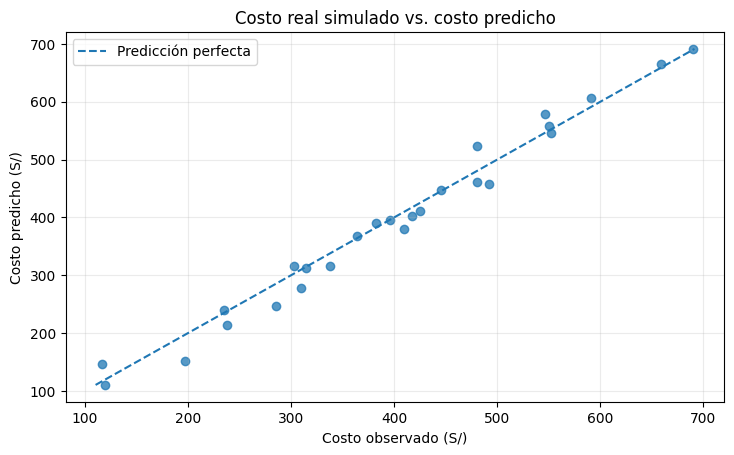

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.scatter(y_prueba, predicciones, alpha=.75)
linea_min = min(y_prueba.min(), predicciones.min())
linea_max = max(y_prueba.max(), predicciones.max())
ax.plot([linea_min, linea_max], [linea_min, linea_max], '--', label='Predicción perfecta')
ax.set_title('Costo real simulado vs. costo predicho')
ax.set_xlabel('Costo observado (S/)')
ax.set_ylabel('Costo predicho (S/)')
ax.legend()
ax.grid(alpha=.25)
plt.show()

**Interpretación de la gráfica:** cada punto representa un viaje de prueba. Si un punto queda cerca de la línea diagonal, el resultado predicho se aproxima al costo registrado. La dispersión alrededor de esa diagonal explica por qué existe un error promedio distinto de cero.

## 5. Paso 3 — Guardar el modelo en JSON
En el sitio web no se recalcula la regresión cada vez que alguien entra. Entrenamos una vez y guardamos los coeficientes para que Flask utilice exactamente esa misma ecuación.

In [4]:
import json
from pathlib import Path

modelo_exportado = {
    'intercepto': float(modelo.intercept_),
    'coeficientes': {nombre: float(valor) for nombre, valor in zip(columnas, modelo.coef_)},
    'variables': columnas,
    'objetivo': objetivo,
    'metricas': {
        'mae': float(mae),
        'r2': float(r2),
        'filas_entrenamiento': len(X_ent),
        'filas_prueba': len(X_prueba)
    },
    'nota': 'Modelo académico basado en 130 viajes simulados. No es una tarifa contractual.'
}
Path('modelo.json').write_text(json.dumps(modelo_exportado, ensure_ascii=False, indent=2), encoding='utf-8')
print('Modelo guardado en modelo.json')

Modelo guardado en modelo.json


## 6. Paso 4 — Pruebas obligatorias del instructor
Se deben probar estos escenarios desde el notebook y después desde la página web:

1. **Viaje 25 km, 400 kg y ruta asfaltada (0)**.
2. **Viaje 100 km, 1200 kg y ruta no asfaltada (1)**.

In [5]:
pruebas = pd.DataFrame([
    {'distancia_km': 25, 'carga_kg': 400, 'via_no_asfaltada': 0},
    {'distancia_km': 100, 'carga_kg': 1200, 'via_no_asfaltada': 1},
])
pruebas['costo_estimado_S/'] = modelo.predict(pruebas[columnas]).round(2)
display(pruebas)

,distancia_km,carga_kg,via_no_asfaltada,costo_estimado_S/
0,25,400,0,133.79
1,100,1200,1,454.13


**Respuesta: ¿Qué valores devolvió el sistema y tienen sentido?**

- **Prueba 1:** costo estimado **S/ 133.79** para 25 km, 400 kg y carretera asfaltada. Es coherente con una ruta corta y carga moderada.
- **Prueba 2:** costo estimado **S/ 454.13** para 100 km, 1200 kg y carretera no asfaltada. Es mayor por la distancia, el peso y el efecto de la vía.

**¿En qué circunstancias podría fallar?** En recorridos fuera de los rangos evaluados, en situaciones con peajes, lluvias intensas, caminos peligrosos, combustible costoso, horas de espera, carga especial o registros con errores. También puede fallar porque los costos reales varían y el conjunto de datos es simulado.

## 7. Paso 5 — Aplicación web con Flask
Se entregan `app.py`, `templates/index.html` y `static/estilos.css`. La página funciona con **Python + Flask + HTML + CSS, sin JavaScript**. Lee `modelo.json`, admite los tres datos, calcula la predicción, informa el desglose del costo y muestra advertencias de uso.

**Validaciones:** distancia entre **3 y 165 km**; carga entre **50 y 2050 kg**; tipo de vía **0 o 1**. Los formularios incluyen también botones con las pruebas del instructor.

**Enlace público del Caso 02:** https://senati-caso-02-transporte-agricola.onrender.com

**Capturas requeridas:** `evidencias/prueba_01_25km_400kg_asfaltada.png` y `evidencias/prueba_02_100km_1200kg_no_asfaltada.png`. Se toman con la página abierta y el resultado visible.

## 8. Explicación del proyecto en 10 líneas
1. El proyecto busca estimar el costo de transportar productos agrícolas.
2. Se utilizó el archivo original de 130 viajes simulados del instructor.
3. Se revisaron los datos y se comprobó que no contienen ausentes.
4. Las variables predictoras fueron distancia, peso y tipo de vía.
5. La variable a predecir fue el costo de transporte en soles.
6. Se separó el 80 % de los datos para entrenar y el 20 % para probar.
7. Se entrenó un modelo de regresión lineal múltiple de Scikit-learn.
8. El error absoluto medio en prueba fue aproximadamente S/ 17.79.
9. Se guardaron los coeficientes en JSON y se creó una web Flask para calcular.
10. La página muestra resultados orientativos y advierte que no representan tarifas reales.

## 9. Conclusiones y limitaciones

**Conclusión 1.** La regresión lineal múltiple permitió combinar tres características de un viaje para estimar su costo, mostrando cómo un algoritmo transforma datos en un resultado numérico.

**Conclusión 2.** La comparación entre las dos pruebas demuestra que mayores distancias, mayor carga y una vía no asfaltada producen una estimación más alta para el modelo entrenado.

**Conclusión 3.** Un MAE de alrededor de S/ 17.79 y R² de 0.9772 en estos datos de prueba muestran buen ajuste, aunque no implican precisión perfecta.

**Limitación 1.** Los datos son simulados; cualquier aplicación real requiere datos de transporte verificados y actuales.

**Limitación 2.** No se consideran factores como combustible, peajes, seguridad, tráfico, tipo de vehículo y estación del año.

**Mejora propuesta.** Recopilar viajes reales, agregar nuevas variables justificadas y comparar modelos con validación cruzada manteniendo un conjunto final de prueba independiente.